---
## Phase 3 — Interpretable Interference Detection

Two spectral features are evaluated:

1. Relative mains-frequency power within ±2 Hz.
2. Local spectral prominence relative to nearby frequencies.

These features describe different characteristics
of narrowband interference.

The detector is designed specifically for
power-line interference, not all EEG artifacts.

NEUROSIGNAL-QC — SPECTRAL FEATURE DATASET

EEG clips selected: 225

Processing hospital: Mayo

Processing hospital: FNUSA

FEATURE DATASET INTEGRITY
Total EEG clips: 225
Unique participants: 38
Missing prominence values: 0

SPECTRAL FEATURE SUMMARY


,Hospital,Category,Clips,Subjects,Median_Relative_Power,Median_Prominence_dB,Min_Prominence_dB,Max_Prominence_dB
0,FNUSA,Artifact,30,10,0.0650,4.1246,-2.9608,12.1369
1,FNUSA,Pathological,30,12,0.1036,5.8645,-3.5975,10.4202
2,FNUSA,Physiological,30,9,0.0508,6.7073,0.5287,12.2179
3,FNUSA,Power-line,15,3,50.9039,32.8680,27.2480,43.4270
4,Mayo,Artifact,30,14,0.1757,9.8380,1.8686,28.0261
5,Mayo,Pathological,30,6,0.0589,6.1010,-1.0351,28.5226
6,Mayo,Physiological,30,13,0.1174,12.1560,2.3234,35.0413
7,Mayo,Power-line,30,8,30.9325,35.6315,14.6892,47.5247


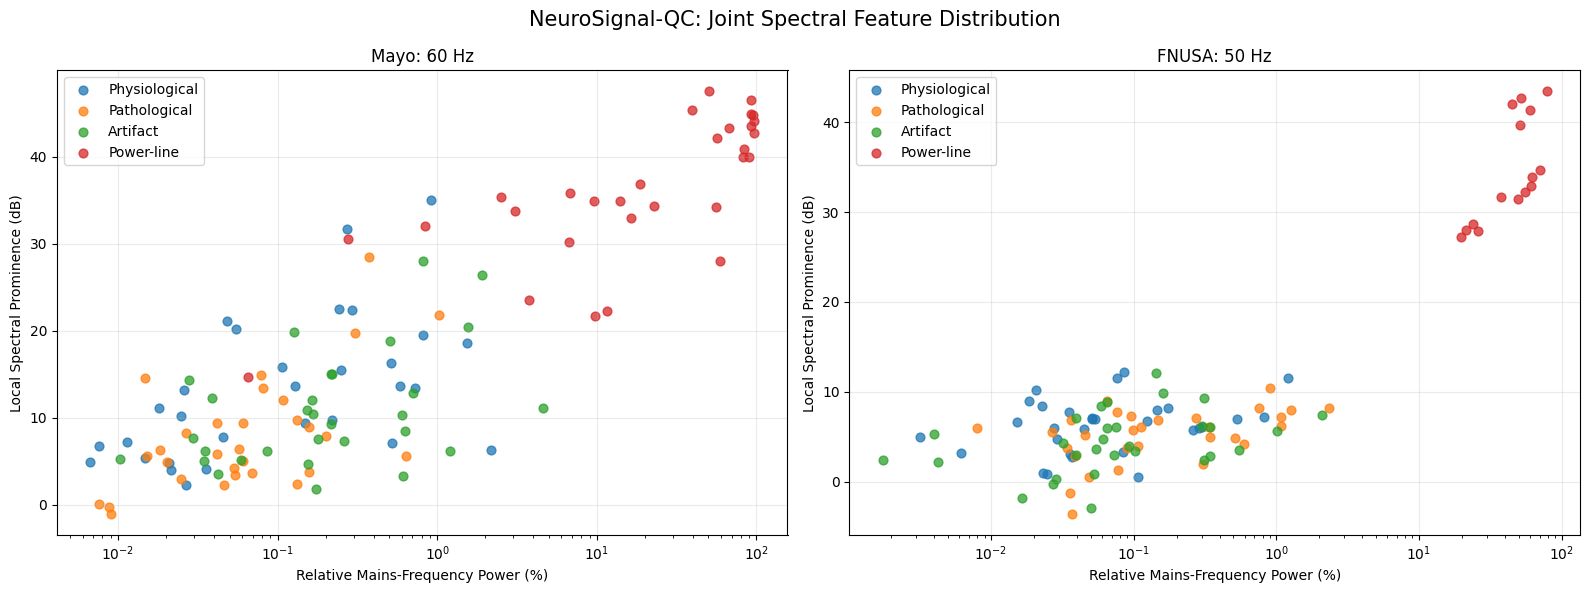


LOCAL PROMINENCE OVERLAP ANALYSIS

Mayo
Minimum power-line prominence: 14.689 dB
Maximum non-power-line prominence: 35.041 dB
Power-line clips within the non-power-line prominence range: 14 / 30

FNUSA
Minimum power-line prominence: 27.248 dB
Maximum non-power-line prominence: 12.218 dB
Power-line clips within the non-power-line prominence range: 0 / 15

Phase 3 feature dataset construction complete.
No classification thresholds or models have been applied.


In [19]:
# ============================================================
# NEUROSIGNAL-QC
# PHASE 3 — CELL 1
# Interpretable Spectral Feature Dataset
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import welch
from IPython.display import display

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

HOSPITALS = ["Mayo", "FNUSA"]

CATEGORIES = [
    "Physiological",
    "Pathological",
    "Artifact",
    "Power-line"
]

MAINS_FREQUENCIES = {
    "Mayo": 60,
    "FNUSA": 50
}

feature_records = []

print("=" * 70)
print("NEUROSIGNAL-QC — SPECTRAL FEATURE DATASET")
print("=" * 70)

# ------------------------------------------------------------
# 2. Prepare recording metadata
# ------------------------------------------------------------

metadata_parts = []

for hospital in HOSPITALS:

    metadata = events[hospital][
        [
            "store_path",
            "sample_index",
            "group_name"
        ]
    ].copy()

    metadata = metadata.rename(
        columns={
            "store_path": "Store",
            "sample_index": "Sample Index"
        }
    )

    metadata["Hospital"] = hospital

    metadata_parts.append(metadata)

recording_metadata = pd.concat(
    metadata_parts,
    ignore_index=True
).drop_duplicates()

# Verify that each clip has unambiguous recording metadata
metadata_keys = [
    "Hospital",
    "Store",
    "Sample Index"
]

if recording_metadata.duplicated(metadata_keys).any():
    raise ValueError(
        "Ambiguous recording metadata detected."
    )

# Join metadata with the 225 previously analyzed recordings
feature_input = expanded_spectral_df.merge(
    recording_metadata,
    on=metadata_keys,
    how="left",
    validate="many_to_one"
)

if feature_input["group_name"].isna().any():
    raise ValueError(
        "Some EEG recordings are missing signal metadata."
    )

print(
    "\nEEG clips selected:",
    len(feature_input)
)

# ------------------------------------------------------------
# 3. Calculate local spectral prominence
# ------------------------------------------------------------

for hospital in HOSPITALS:

    hospital_df = feature_input[
        feature_input["Hospital"] == hospital
    ]

    dataset_id = DATASETS[hospital]

    mains = MAINS_FREQUENCIES[hospital]

    print(f"\nProcessing hospital: {hospital}")

    for _, row in hospital_df.iterrows():

        store_path = row["Store"]
        group_name = row["group_name"]

        start = int(row["Sample Index"])

        # Reuse the remote recordings from Phase 2
        cache_key = (
            dataset_id,
            store_path
        )

        if cache_key not in opened_stores:
            raise ValueError(
                "Recording not cached. Run Phase 2 Cell 8 first."
            )

        root = opened_stores[cache_key]

        group = root[group_name]

        signal_array = group["0"]

        fs = float(group.attrs["rate"])

        n_samples = int(round(3 * fs))

        # ----------------------------------------------------
        # 4. Retrieve the EEG signal
        # ----------------------------------------------------

        digital = np.asarray(
            signal_array[
                0,
                start:start + n_samples
            ],
            dtype=np.float64
        )

        if len(digital) != n_samples:
            raise ValueError(
                "Incomplete EEG segment encountered."
            )

        scale = float(
            signal_array.attrs["scale"][0]
        )

        offset = float(
            signal_array.attrs["offset"][0]
        )

        eeg = digital * scale + offset

        if not np.all(np.isfinite(eeg)):
            raise ValueError(
                "Nonfinite EEG samples encountered."
            )

        # ----------------------------------------------------
        # 5. Welch Power Spectral Density
        # ----------------------------------------------------

        frequencies, psd = welch(
            eeg,
            fs=fs,
            window="hann",
            nperseg=2048,
            noverlap=1024,
            detrend="constant",
            scaling="density"
        )

        # ----------------------------------------------------
        # 6. Identify peak near the expected mains frequency
        # ----------------------------------------------------

        peak_mask = (
            (frequencies >= mains - 2)
            &
            (frequencies <= mains + 2)
        )

        peak_values = psd[peak_mask]

        peak_frequencies = frequencies[peak_mask]

        peak_index = int(
            np.argmax(peak_values)
        )

        peak_power = float(
            peak_values[peak_index]
        )

        detected_frequency = float(
            peak_frequencies[peak_index]
        )

        # ----------------------------------------------------
        # 7. Estimate local spectral background
        # ----------------------------------------------------

        background_mask = (
            (
                (frequencies >= mains - 15)
                &
                (frequencies <= mains - 5)
            )
            |
            (
                (frequencies >= mains + 5)
                &
                (frequencies <= mains + 15)
            )
        )

        background_power = float(
            np.median(psd[background_mask])
        )

        # ----------------------------------------------------
        # 8. Calculate spectral prominence
        # ----------------------------------------------------

        if background_power > 0:

            prominence_db = (
                10 * np.log10(
                    peak_power / background_power
                )
            )

        else:

            prominence_db = np.nan

        # ----------------------------------------------------
        # 9. Store both spectral features
        # ----------------------------------------------------

        feature_records.append({
            "Hospital": hospital,
            "Subject": str(row["Subject"]),
            "Category": row["Category"],
            "Store": store_path,
            "Sample Index": start,
            "Relative Mains Power (%)":
                row["Relative Mains Power (%)"],
            "Local Prominence (dB)":
                prominence_db,
            "Detected Peak (Hz)":
                detected_frequency,
            "Peak Offset (Hz)":
                detected_frequency - mains
        })

# ============================================================
# 10. Create feature dataset
# ============================================================

phase3_features_df = pd.DataFrame(
    feature_records
)

print("\n" + "=" * 70)
print("FEATURE DATASET INTEGRITY")
print("=" * 70)

print(
    "Total EEG clips:",
    len(phase3_features_df)
)

print(
    "Unique participants:",
    phase3_features_df[
        ["Hospital", "Subject"]
    ].drop_duplicates().shape[0]
)

print(
    "Missing prominence values:",
    phase3_features_df[
        "Local Prominence (dB)"
    ].isna().sum()
)

assert len(phase3_features_df) == len(expanded_spectral_df)

assert phase3_features_df[
    "Local Prominence (dB)"
].notna().all()

# ============================================================
# 11. Summarize feature distributions
# ============================================================

print("\n" + "=" * 70)
print("SPECTRAL FEATURE SUMMARY")
print("=" * 70)

feature_summary = (
    phase3_features_df
    .groupby(
        ["Hospital", "Category"],
        observed=True
    )
    .agg(
        Clips=("Subject", "count"),
        Subjects=("Subject", "nunique"),
        Median_Relative_Power=(
            "Relative Mains Power (%)",
            "median"
        ),
        Median_Prominence_dB=(
            "Local Prominence (dB)",
            "median"
        ),
        Min_Prominence_dB=(
            "Local Prominence (dB)",
            "min"
        ),
        Max_Prominence_dB=(
            "Local Prominence (dB)",
            "max"
        )
    )
    .reset_index()
)

display(feature_summary.round(4))

# ============================================================
# 12. Visualize the two features together
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

for i, hospital in enumerate(HOSPITALS):

    ax = axes[i]

    hospital_df = phase3_features_df[
        phase3_features_df["Hospital"] == hospital
    ]

    for category in CATEGORIES:

        subset = hospital_df[
            hospital_df["Category"] == category
        ]

        ax.scatter(
            subset["Relative Mains Power (%)"],
            subset["Local Prominence (dB)"],
            alpha=0.75,
            s=40,
            label=category
        )

    ax.set_xscale("log")

    ax.set_xlabel(
        "Relative Mains-Frequency Power (%)"
    )

    ax.set_ylabel(
        "Local Spectral Prominence (dB)"
    )

    ax.set_title(
        f"{hospital}: {MAINS_FREQUENCIES[hospital]} Hz"
    )

    ax.grid(alpha=0.25)

    ax.legend()

plt.suptitle(
    "NeuroSignal-QC: Joint Spectral Feature Distribution",
    fontsize=15
)

plt.tight_layout()

plt.show()

# ============================================================
# 13. Examine feature overlap
# ============================================================

print("\n" + "=" * 70)
print("LOCAL PROMINENCE OVERLAP ANALYSIS")
print("=" * 70)

for hospital in HOSPITALS:

    hospital_df = phase3_features_df[
        phase3_features_df["Hospital"] == hospital
    ]

    powerline = hospital_df[
        hospital_df["Category"] == "Power-line"
    ]

    non_powerline = hospital_df[
        hospital_df["Category"] != "Power-line"
    ]

    min_powerline = powerline[
        "Local Prominence (dB)"
    ].min()

    max_non_powerline = non_powerline[
        "Local Prominence (dB)"
    ].max()

    overlapping = powerline[
        powerline["Local Prominence (dB)"]
        <= max_non_powerline
    ]

    print(f"\n{hospital}")

    print(
        "Minimum power-line prominence:",
        round(min_powerline, 3),
        "dB"
    )

    print(
        "Maximum non-power-line prominence:",
        round(max_non_powerline, 3),
        "dB"
    )

    print(
        "Power-line clips within the "
        "non-power-line prominence range:",
        len(overlapping),
        "/",
        len(powerline)
    )

print("\nPhase 3 feature dataset construction complete.")
print("No classification thresholds or models have been applied.")

### Participant-Disjoint Evaluation Design

The dataset is divided into development and
evaluation groups at the participant level.

No participant belongs to both groups.

Feature exploration preceded this split, so the
evaluation is retrospective rather than fully blinded.

In [20]:
# ============================================================
# NEUROSIGNAL-QC
# PHASE 3 — CELL 2
# Participant-Independent Development / Evaluation Split
# ============================================================

import numpy as np
import pandas as pd

from IPython.display import display

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

CATEGORIES = [
    "Physiological",
    "Pathological",
    "Artifact",
    "Power-line"
]

# Number of participants assigned to evaluation
TEST_SUBJECTS = {
    "Mayo": 6,
    "FNUSA": 4
}

# Ensure power-line participants appear in both groups
TEST_POWERLINE_SUBJECTS = {
    "Mayo": 2,
    "FNUSA": 1
}

MAX_ATTEMPTS = 10000

# ------------------------------------------------------------
# 2. Prepare the existing feature dataset
# ------------------------------------------------------------

df = phase3_features_df.copy()

df["Hospital"] = df["Hospital"].astype(str)

df["Subject"] = (
    df["Subject"]
    .astype(str)
    .str.replace(r"^sub-", "", regex=True)
    .str.zfill(3)
)

df["Category"] = df["Category"].astype(str)

# Create globally unique participant identifiers
df["Patient_ID"] = (
    df["Hospital"] + "_" + df["Subject"]
)

# Binary target for future power-line detection
df["Powerline_Label"] = (
    df["Category"] == "Power-line"
).astype(int)

# ------------------------------------------------------------
# 3. Data integrity checks
# ------------------------------------------------------------

required_features = [
    "Relative Mains Power (%)",
    "Local Prominence (dB)"
]

assert len(df) == 225, (
    "Unexpected number of EEG clips."
)

assert not df.duplicated(
    ["Hospital", "Store", "Sample Index"]
).any(), "Duplicate EEG clips detected."

assert np.isfinite(
    df[required_features].to_numpy(dtype=float)
).all(), "Invalid spectral feature values."

print("=" * 70)
print("NEUROSIGNAL-QC — PARTICIPANT-INDEPENDENT SPLIT")
print("=" * 70)

print("\nTotal EEG clips:", len(df))
print("Total participants:", df["Patient_ID"].nunique())

# ------------------------------------------------------------
# 4. Identify eligible participants by hospital
# ------------------------------------------------------------

hospital_subjects = {}

for hospital in ["Mayo", "FNUSA"]:

    hospital_df = df[
        df["Hospital"] == hospital
    ]

    all_subjects = set(
        hospital_df["Patient_ID"].unique()
    )

    powerline_subjects = set(
        hospital_df.loc[
            hospital_df["Category"] == "Power-line",
            "Patient_ID"
        ].unique()
    )

    other_subjects = (
        all_subjects - powerline_subjects
    )

    hospital_subjects[hospital] = {
        "all": sorted(all_subjects),
        "powerline": sorted(powerline_subjects),
        "other": sorted(other_subjects)
    }

    print(f"\n{hospital}")
    print("Participants:", len(all_subjects))
    print(
        "Participants with power-line recordings:",
        len(powerline_subjects)
    )

# ------------------------------------------------------------
# 5. Generate participant-level splits
# ------------------------------------------------------------

# Sampling uses patient IDs and annotation coverage only.
# Spectral feature values are NOT used to choose the split.

valid_split = False

for attempt in range(MAX_ATTEMPTS):

    evaluation_patients = set()

    for hospital in ["Mayo", "FNUSA"]:

        info = hospital_subjects[hospital]

        n_test = TEST_SUBJECTS[hospital]

        n_powerline = TEST_POWERLINE_SUBJECTS[hospital]

        # Select evaluation participants who contribute
        # power-line recordings
        selected_powerline = rng.choice(
            info["powerline"],
            size=n_powerline,
            replace=False
        )

        # Select remaining evaluation participants
        selected_other = rng.choice(
            info["other"],
            size=n_test - n_powerline,
            replace=False
        )

        evaluation_patients.update(
            selected_powerline.tolist()
        )

        evaluation_patients.update(
            selected_other.tolist()
        )

    candidate = df.copy()

    candidate["Split"] = np.where(
        candidate["Patient_ID"].isin(
            evaluation_patients
        ),
        "Evaluation",
        "Development"
    )

    # --------------------------------------------------------
    # 6. Verify annotation coverage
    # --------------------------------------------------------

    coverage_valid = True

    for hospital in ["Mayo", "FNUSA"]:

        for split_name in [
            "Development",
            "Evaluation"
        ]:

            subset = candidate[
                (candidate["Hospital"] == hospital)
                &
                (candidate["Split"] == split_name)
            ]

            available_categories = set(
                subset["Category"].unique()
            )

            if not set(CATEGORIES).issubset(
                available_categories
            ):
                coverage_valid = False
                break

        if not coverage_valid:
            break

    if coverage_valid:

        valid_split = True

        phase3_split_df = candidate.copy()

        break

if not valid_split:
    raise RuntimeError(
        "Could not construct a participant split "
        "with all categories represented."
    )

# ============================================================
# 7. Create development and evaluation datasets
# ============================================================

phase3_train_df = phase3_split_df[
    phase3_split_df["Split"] == "Development"
].copy()

phase3_test_df = phase3_split_df[
    phase3_split_df["Split"] == "Evaluation"
].copy()

# ------------------------------------------------------------
# 8. Verify participant independence
# ------------------------------------------------------------

development_patients = set(
    phase3_train_df["Patient_ID"]
)

evaluation_patients = set(
    phase3_test_df["Patient_ID"]
)

participant_overlap = (
    development_patients
    &
    evaluation_patients
)

assert len(participant_overlap) == 0, (
    "DATA LEAKAGE: Participants overlap!"
)

assert (
    len(phase3_train_df)
    +
    len(phase3_test_df)
    ==
    len(df)
), "Some EEG clips were lost."

# ============================================================
# 9. Display split summary
# ============================================================

print("\n" + "=" * 70)
print("DEVELOPMENT / EVALUATION SUMMARY")
print("=" * 70)

split_summary = (
    phase3_split_df
    .groupby(
        ["Hospital", "Split"],
        observed=True
    )
    .agg(
        Clips=("Patient_ID", "count"),
        Participants=("Patient_ID", "nunique"),
        Powerline_Clips=(
            "Powerline_Label",
            "sum"
        )
    )
    .reset_index()
)

display(split_summary)

# ============================================================
# 10. Annotation distribution
# ============================================================

print("\n" + "=" * 70)
print("ANNOTATION DISTRIBUTION BY SPLIT")
print("=" * 70)

category_summary = (
    phase3_split_df
    .groupby(
        ["Hospital", "Split", "Category"],
        observed=True
    )
    .agg(
        Clips=("Patient_ID", "count"),
        Participants=("Patient_ID", "nunique")
    )
    .reset_index()
)

display(category_summary)

# ============================================================
# 11. Final verification
# ============================================================

print("\n" + "=" * 70)
print("PARTICIPANT INDEPENDENCE VERIFICATION")
print("=" * 70)

print(
    "Development participants:",
    len(development_patients)
)

print(
    "Evaluation participants:",
    len(evaluation_patients)
)

print(
    "Overlapping participants:",
    len(participant_overlap)
)

print(
    "Development EEG clips:",
    len(phase3_train_df)
)

print(
    "Evaluation EEG clips:",
    len(phase3_test_df)
)

print(
    "\nSplit generated after",
    attempt + 1,
    "attempt(s)."
)

print("\nParticipant-disjoint split verified.")
print("No detection model has been trained.")

NEUROSIGNAL-QC — PARTICIPANT-INDEPENDENT SPLIT

Total EEG clips: 225
Total participants: 38

Mayo
Participants: 24
Participants with power-line recordings: 8

FNUSA
Participants: 14
Participants with power-line recordings: 3

DEVELOPMENT / EVALUATION SUMMARY


,Hospital,Split,Clips,Participants,Powerline_Clips
0,FNUSA,Development,65,10,10
1,FNUSA,Evaluation,40,4,5
2,Mayo,Development,89,18,22
3,Mayo,Evaluation,31,6,8



ANNOTATION DISTRIBUTION BY SPLIT


,Hospital,Split,Category,Clips,Participants
0,FNUSA,Development,Artifact,18,6
1,FNUSA,Development,Pathological,21,8
2,FNUSA,Development,Physiological,16,5
3,FNUSA,Development,Power-line,10,2
4,FNUSA,Evaluation,Artifact,12,4
5,FNUSA,Evaluation,Pathological,9,4
6,FNUSA,Evaluation,Physiological,14,4
7,FNUSA,Evaluation,Power-line,5,1
8,Mayo,Development,Artifact,22,10
9,Mayo,Development,Pathological,25,5



PARTICIPANT INDEPENDENCE VERIFICATION
Development participants: 28
Evaluation participants: 10
Overlapping participants: 0
Development EEG clips: 154
Evaluation EEG clips: 71

Split generated after 1 attempt(s).

Participant-disjoint split verified.
No detection model has been trained.


### Development-Only Threshold Selection

We compare relative-power, prominence, OR, and AND rules.

Candidate thresholds are defined using the 95th
percentile of non-power-line development recordings.

The conservative AND rule is selected based on
its development-set trade-off between power-line
detection and false alarms.

In [21]:
# ============================================================
# NEUROSIGNAL-QC
# PHASE 3 — CELL 3
# Development-Only Interpretable Detection Rules
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

POWER_FEATURE = "Relative Mains Power (%)"
PROMINENCE_FEATURE = "Local Prominence (dB)"

THRESHOLD_PERCENTILE = 95

# IMPORTANT:
# Only development data will be used in this cell.
# Evaluation recordings remain untouched.

dev_df = phase3_train_df.copy()

# ------------------------------------------------------------
# 2. Verify development dataset
# ------------------------------------------------------------

required_columns = [
    "Hospital",
    "Subject",
    "Category",
    "Powerline_Label",
    POWER_FEATURE,
    PROMINENCE_FEATURE
]

missing_columns = [
    col for col in required_columns
    if col not in dev_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

assert len(dev_df) == 154, (
    "Unexpected development dataset size."
)

assert np.isfinite(
    dev_df[
        [POWER_FEATURE, PROMINENCE_FEATURE]
    ].to_numpy(dtype=float)
).all(), "Invalid feature values detected."

print("=" * 70)
print("NEUROSIGNAL-QC — DEVELOPMENT-ONLY DETECTOR ANALYSIS")
print("=" * 70)

print("\nDevelopment recordings:", len(dev_df))

print(
    "Development participants:",
    dev_df["Patient_ID"].nunique()
)

# ------------------------------------------------------------
# 3. Separate annotation groups
# ------------------------------------------------------------

powerline_mask = (
    dev_df["Powerline_Label"] == 1
)

non_powerline_mask = ~powerline_mask

pathological_mask = (
    dev_df["Category"] == "Pathological"
)

print("\nAnnotation counts:")

print(
    "Power-line:",
    int(powerline_mask.sum())
)

print(
    "Non-power-line:",
    int(non_powerline_mask.sum())
)

print(
    "Pathological:",
    int(pathological_mask.sum())
)

# ------------------------------------------------------------
# 4. Derive thresholds from development data only
# ------------------------------------------------------------

non_powerline_dev = dev_df.loc[
    non_powerline_mask
]

power_threshold = float(
    np.percentile(
        non_powerline_dev[POWER_FEATURE],
        THRESHOLD_PERCENTILE
    )
)

prominence_threshold = float(
    np.percentile(
        non_powerline_dev[PROMINENCE_FEATURE],
        THRESHOLD_PERCENTILE
    )
)

thresholds_df = pd.DataFrame({
    "Feature": [
        POWER_FEATURE,
        PROMINENCE_FEATURE
    ],
    "Percentile": [
        THRESHOLD_PERCENTILE,
        THRESHOLD_PERCENTILE
    ],
    "Threshold": [
        power_threshold,
        prominence_threshold
    ]
})

print("\n" + "=" * 70)
print("DEVELOPMENT-DERIVED THRESHOLDS")
print("=" * 70)

display(thresholds_df.round(4))

# ------------------------------------------------------------
# 5. Apply individual detection rules
# ------------------------------------------------------------

power_flag = (
    dev_df[POWER_FEATURE].to_numpy()
    > power_threshold
)

prominence_flag = (
    dev_df[PROMINENCE_FEATURE].to_numpy()
    > prominence_threshold
)

# Four candidate detection rules
rule_predictions = {
    "Relative Power Only": power_flag,
    "Prominence Only": prominence_flag,
    "Either Feature (OR)": (
        power_flag | prominence_flag
    ),
    "Both Features (AND)": (
        power_flag & prominence_flag
    )
}

# ------------------------------------------------------------
# 6. Calculate development performance
# ------------------------------------------------------------

y_true = powerline_mask.to_numpy()

pathology = pathological_mask.to_numpy()

non_powerline = non_powerline_mask.to_numpy()

results = []

for rule_name, predictions in rule_predictions.items():

    predictions = np.asarray(
        predictions,
        dtype=bool
    )

    # Power-line detection
    true_positives = np.sum(
        predictions & y_true
    )

    false_negatives = np.sum(
        (~predictions) & y_true
    )

    # Non-power-line false alarms
    false_positives = np.sum(
        predictions & non_powerline
    )

    true_negatives = np.sum(
        (~predictions) & non_powerline
    )

    # Pathological recordings flagged
    pathological_flags = np.sum(
        predictions & pathology
    )

    sensitivity = (
        100 * true_positives / np.sum(y_true)
    )

    specificity = (
        100 * true_negatives / np.sum(non_powerline)
    )

    false_positive_rate = (
        100 * false_positives / np.sum(non_powerline)
    )

    pathological_fpr = (
        100 * pathological_flags / np.sum(pathology)
    )

    results.append({
        "Rule": rule_name,
        "Sensitivity (%)": sensitivity,
        "Specificity (%)": specificity,
        "Non-Powerline FPR (%)": false_positive_rate,
        "Pathological FPR (%)": pathological_fpr,
        "Powerline Detected": int(true_positives),
        "Powerline Missed": int(false_negatives),
        "Pathological Flagged": int(pathological_flags)
    })

dev_rule_results_df = pd.DataFrame(results)

print("\n" + "=" * 70)
print("DEVELOPMENT PERFORMANCE COMPARISON")
print("=" * 70)

display(
    dev_rule_results_df.round(2)
)

# ------------------------------------------------------------
# 7. Examine performance separately by hospital
# ------------------------------------------------------------

hospital_results = []

for hospital in ["Mayo", "FNUSA"]:

    hospital_indices = (
        dev_df["Hospital"].to_numpy() == hospital
    )

    hospital_positive = (
        hospital_indices & y_true
    )

    hospital_negative = (
        hospital_indices & non_powerline
    )

    hospital_pathological = (
        hospital_indices & pathology
    )

    for rule_name, predictions in rule_predictions.items():

        detected = np.sum(
            predictions & hospital_positive
        )

        positive_total = np.sum(
            hospital_positive
        )

        false_alarms = np.sum(
            predictions & hospital_negative
        )

        negative_total = np.sum(
            hospital_negative
        )

        pathology_flags = np.sum(
            predictions & hospital_pathological
        )

        pathology_total = np.sum(
            hospital_pathological
        )

        hospital_results.append({
            "Hospital": hospital,
            "Rule": rule_name,
            "Powerline Detected": int(detected),
            "Powerline Total": int(positive_total),
            "Sensitivity (%)": (
                100 * detected / positive_total
                if positive_total else np.nan
            ),
            "Non-Powerline FPR (%)": (
                100 * false_alarms / negative_total
                if negative_total else np.nan
            ),
            "Pathological Flagged": int(pathology_flags),
            "Pathological Total": int(pathology_total)
        })

dev_rule_hospital_df = pd.DataFrame(
    hospital_results
)

print("\n" + "=" * 70)
print("HOSPITAL-SPECIFIC DEVELOPMENT RESULTS")
print("=" * 70)

display(
    dev_rule_hospital_df.round(2)
)

# ------------------------------------------------------------
# 8. Final verification
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DEVELOPMENT ANALYSIS COMPLETE")
print("=" * 70)

print("Development clips used:", len(dev_df))
print("Evaluation clips used: 0")

print(
    "\nThresholds derived exclusively "
    "from development data."
)

print(
    "No evaluation predictions generated."
)

print(
    "\nDetection rules are exploratory."
)

NEUROSIGNAL-QC — DEVELOPMENT-ONLY DETECTOR ANALYSIS

Development recordings: 154
Development participants: 28

Annotation counts:
Power-line: 32
Non-power-line: 122
Pathological: 46

DEVELOPMENT-DERIVED THRESHOLDS


,Feature,Percentile,Threshold
0,Relative Mains Power (%),95,1.5287
1,Local Prominence (dB),95,20.4909



DEVELOPMENT PERFORMANCE COMPARISON


,Rule,Sensitivity (%),Specificity (%),Non-Powerline FPR (%),Pathological FPR (%),Powerline Detected,Powerline Missed,Pathological Flagged
0,Relative Power Only,93.75,94.26,5.74,2.17,30,2,1
1,Prominence Only,100.00,94.26,5.74,4.35,32,0,2
2,Either Feature (OR),100.00,90.16,9.84,6.52,32,0,3
3,Both Features (AND),93.75,98.36,1.64,0.00,30,2,0



HOSPITAL-SPECIFIC DEVELOPMENT RESULTS


,Hospital,Rule,Powerline Detected,Powerline Total,Sensitivity (%),Non-Powerline FPR (%),Pathological Flagged,Pathological Total
0,Mayo,Relative Power Only,20,22,90.91,7.46,0,25
1,Mayo,Prominence Only,22,22,100.00,10.45,2,25
2,Mayo,Either Feature (OR),22,22,100.00,14.93,2,25
3,Mayo,Both Features (AND),20,22,90.91,2.99,0,25
4,FNUSA,Relative Power Only,10,10,100.00,3.64,1,21
5,FNUSA,Prominence Only,10,10,100.00,0.00,0,21
6,FNUSA,Either Feature (OR),10,10,100.00,3.64,1,21
7,FNUSA,Both Features (AND),10,10,100.00,0.00,0,21



DEVELOPMENT ANALYSIS COMPLETE
Development clips used: 154
Evaluation clips used: 0

Thresholds derived exclusively from development data.
No evaluation predictions generated.

Detection rules are exploratory.


### Participant-Disjoint Detector Evaluation

The selected AND rule and thresholds are frozen
before evaluating the reserved participants.

Performance is reported using sensitivity,
specificity, precision, and pathological-annotation
flag rates.

A pathological-labeled recording that is not flagged
does not prove that pathological signal content
has been preserved or that the recording is clean.

In [22]:
# ============================================================
# NEUROSIGNAL-QC
# PHASE 3 — CELL 4
# Participant-Independent Detector Evaluation
# ============================================================

import numpy as np
import pandas as pd

from IPython.display import display

# ------------------------------------------------------------
# 1. Freeze the selected detection rule
# ------------------------------------------------------------

FROZEN_RULE = "Both Features (AND)"

POWER_FEATURE = "Relative Mains Power (%)"
PROMINENCE_FEATURE = "Local Prominence (dB)"

# Use the exact thresholds calculated in Cell 3.
# Do NOT manually enter rounded values.

FROZEN_POWER_THRESHOLD = float(power_threshold)
FROZEN_PROMINENCE_THRESHOLD = float(prominence_threshold)

print("=" * 70)
print("NEUROSIGNAL-QC — PARTICIPANT-INDEPENDENT EVALUATION")
print("=" * 70)

print("\nSelected detector:", FROZEN_RULE)

print(
    "Relative mains power threshold:",
    round(FROZEN_POWER_THRESHOLD, 6),
    "%"
)

print(
    "Local prominence threshold:",
    round(FROZEN_PROMINENCE_THRESHOLD, 6),
    "dB"
)

# ------------------------------------------------------------
# 2. Load the reserved evaluation dataset
# ------------------------------------------------------------

eval_df = phase3_test_df.copy()

dev_df = phase3_train_df.copy()

print("\nEvaluation clips:", len(eval_df))

print(
    "Evaluation participants:",
    eval_df["Patient_ID"].nunique()
)

# ------------------------------------------------------------
# 3. Verify participant independence
# ------------------------------------------------------------

development_patients = set(
    dev_df["Patient_ID"]
)

evaluation_patients = set(
    eval_df["Patient_ID"]
)

overlap = (
    development_patients
    &
    evaluation_patients
)

assert len(overlap) == 0, (
    "Participant leakage detected!"
)

assert len(eval_df) == 71, (
    "Unexpected evaluation dataset size."
)

assert np.isfinite(
    eval_df[
        [POWER_FEATURE, PROMINENCE_FEATURE]
    ].to_numpy(dtype=float)
).all(), "Invalid evaluation feature values."

print("\nParticipant overlap:", len(overlap))

print("Participant independence verified.")

# ------------------------------------------------------------
# 4. Apply the frozen AND rule
# ------------------------------------------------------------

power_condition = (
    eval_df[POWER_FEATURE]
    > FROZEN_POWER_THRESHOLD
)

prominence_condition = (
    eval_df[PROMINENCE_FEATURE]
    > FROZEN_PROMINENCE_THRESHOLD
)

eval_df["Predicted_Powerline"] = (
    power_condition & prominence_condition
).astype(int)

eval_df["Actual_Powerline"] = (
    eval_df["Category"] == "Power-line"
).astype(int)

# Save evaluation predictions
phase3_eval_results_df = eval_df.copy()

# ------------------------------------------------------------
# 5. Calculate evaluation metrics
# ------------------------------------------------------------

def calculate_detection_metrics(data):

    actual = data["Actual_Powerline"].to_numpy(
        dtype=bool
    )

    predicted = data["Predicted_Powerline"].to_numpy(
        dtype=bool
    )

    pathological = (
        data["Category"].to_numpy()
        == "Pathological"
    )

    # Confusion matrix components

    tp = int(np.sum(predicted & actual))
    fn = int(np.sum(~predicted & actual))

    fp = int(np.sum(predicted & ~actual))
    tn = int(np.sum(~predicted & ~actual))

    # Pathological recordings incorrectly flagged

    pathological_total = int(
        np.sum(pathological)
    )

    pathological_flagged = int(
        np.sum(predicted & pathological)
    )

    # Performance metrics

    sensitivity = (
        100 * tp / (tp + fn)
        if (tp + fn) > 0 else np.nan
    )

    specificity = (
        100 * tn / (tn + fp)
        if (tn + fp) > 0 else np.nan
    )

    pathological_fpr = (
        100 * pathological_flagged / pathological_total
        if pathological_total > 0 else np.nan
    )

    precision = (
        100 * tp / (tp + fp)
        if (tp + fp) > 0 else np.nan
    )

    return {
        "Clips": len(data),
        "TP": tp,
        "FN": fn,
        "FP": fp,
        "TN": tn,
        "Sensitivity (%)": sensitivity,
        "Specificity (%)": specificity,
        "Precision (%)": precision,
        "Pathological Clips": pathological_total,
        "Pathological Flagged": pathological_flagged,
        "Pathological FPR (%)": pathological_fpr
    }


# ------------------------------------------------------------
# 6. Overall evaluation performance
# ------------------------------------------------------------

overall_metrics = calculate_detection_metrics(
    eval_df
)

overall_results_df = pd.DataFrame(
    [overall_metrics]
)

print("\n" + "=" * 70)
print("OVERALL EVALUATION PERFORMANCE")
print("=" * 70)

display(
    overall_results_df.round(2)
)

# ------------------------------------------------------------
# 7. Hospital-specific performance
# ------------------------------------------------------------

hospital_results = []

for hospital in ["Mayo", "FNUSA"]:

    subset = eval_df[
        eval_df["Hospital"] == hospital
    ]

    metrics = calculate_detection_metrics(
        subset
    )

    metrics["Hospital"] = hospital

    metrics["Participants"] = (
        subset["Patient_ID"].nunique()
    )

    hospital_results.append(metrics)

hospital_results_df = pd.DataFrame(
    hospital_results
)

print("\n" + "=" * 70)
print("HOSPITAL-SPECIFIC EVALUATION")
print("=" * 70)

display(
    hospital_results_df.round(2)
)

# ------------------------------------------------------------
# 8. Examine predictions by annotation category
# ------------------------------------------------------------

category_results = (
    eval_df
    .groupby(
        ["Hospital", "Category"],
        observed=True
    )
    .agg(
        Clips=("Patient_ID", "count"),
        Participants=("Patient_ID", "nunique"),
        Flagged=("Predicted_Powerline", "sum")
    )
    .reset_index()
)

category_results["Not_Flagged"] = (
    category_results["Clips"]
    - category_results["Flagged"]
)

category_results["Flagged_Percentage"] = (
    100
    * category_results["Flagged"]
    / category_results["Clips"]
)

print("\n" + "=" * 70)
print("DETECTION RESULTS BY EEG CATEGORY")
print("=" * 70)

display(
    category_results.round(2)
)

# ------------------------------------------------------------
# 9. Identify incorrectly classified recordings
# ------------------------------------------------------------

false_negative_mask = (
    (eval_df["Actual_Powerline"] == 1)
    &
    (eval_df["Predicted_Powerline"] == 0)
)

false_positive_mask = (
    (eval_df["Actual_Powerline"] == 0)
    &
    (eval_df["Predicted_Powerline"] == 1)
)

error_df = eval_df[
    false_negative_mask | false_positive_mask
].copy()

error_df["Error_Type"] = np.where(
    error_df["Actual_Powerline"] == 1,
    "Missed Power-line",
    "Flagged Other Category"
)

print("\n" + "=" * 70)
print("MISCLASSIFIED EEG RECORDINGS")
print("=" * 70)

if len(error_df) > 0:

    display(
        error_df[
            [
                "Hospital",
                "Subject",
                "Category",
                "Error_Type",
                POWER_FEATURE,
                PROMINENCE_FEATURE
            ]
        ].round(4)
    )

else:

    print(
        "No classification disagreements "
        "in the evaluation sample."
    )

# ------------------------------------------------------------
# 10. Final evaluation verification
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EVALUATION COMPLETE")
print("=" * 70)

print(
    "Evaluation recordings:",
    len(eval_df)
)

print(
    "Evaluation participants:",
    len(evaluation_patients)
)

print(
    "Participant overlap:",
    len(overlap)
)

print(
    "Total classification disagreements:",
    len(error_df)
)

print("\nDetector:", FROZEN_RULE)

print(
    "Thresholds were derived from "
    "development data only."
)

print(
    "No thresholds were adjusted "
    "using evaluation recordings."
)

print(
    "\nEvaluation is retrospective "
    "and exploratory, not clinical validation."
)

NEUROSIGNAL-QC — PARTICIPANT-INDEPENDENT EVALUATION

Selected detector: Both Features (AND)
Relative mains power threshold: 1.528722 %
Local prominence threshold: 20.490936 dB

Evaluation clips: 71
Evaluation participants: 10

Participant overlap: 0
Participant independence verified.

OVERALL EVALUATION PERFORMANCE


,Clips,TP,FN,FP,TN,Sensitivity (%),Specificity (%),Precision (%),Pathological Clips,Pathological Flagged,Pathological FPR (%)
0,71,12,1,0,58,92.31,100.0,100.0,14,0,0.0



HOSPITAL-SPECIFIC EVALUATION


,Clips,TP,FN,FP,TN,Sensitivity (%),Specificity (%),Precision (%),Pathological Clips,Pathological Flagged,Pathological FPR (%),Hospital,Participants
0,31,7,1,0,23,87.5,100.0,100.0,5,0,0.0,Mayo,6
1,40,5,0,0,35,100.0,100.0,100.0,9,0,0.0,FNUSA,4



DETECTION RESULTS BY EEG CATEGORY


,Hospital,Category,Clips,Participants,Flagged,Not_Flagged,Flagged_Percentage
0,FNUSA,Artifact,12,4,0,12,0.0
1,FNUSA,Pathological,9,4,0,9,0.0
2,FNUSA,Physiological,14,4,0,14,0.0
3,FNUSA,Power-line,5,1,5,0,100.0
4,Mayo,Artifact,8,4,0,8,0.0
5,Mayo,Pathological,5,1,0,5,0.0
6,Mayo,Physiological,10,4,0,10,0.0
7,Mayo,Power-line,8,2,7,1,87.5



MISCLASSIFIED EEG RECORDINGS


,Hospital,Subject,Category,Error_Type,Relative Mains Power (%),Local Prominence (dB)
92,Mayo,016,Power-line,Missed Power-line,0.0652,14.6892



EVALUATION COMPLETE
Evaluation recordings: 71
Evaluation participants: 10
Participant overlap: 0
Total classification disagreements: 1

Detector: Both Features (AND)
Thresholds were derived from development data only.
No thresholds were adjusted using evaluation recordings.

Evaluation is retrospective and exploratory, not clinical validation.
